<h1 style="text-align: center;">Assingment 2</h1>

### Task a


In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
from typing import Dict, List, Union


def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = None, names: List[str] = None) -> None:
    if layout is None:
        layout = {} 
    y = [y] if all(isinstance(item, (float, int, np.floating, np.integer)) for item in y) else y
    
    figsize = layout.get('figsize', (8, 4))
    plt.figure(figsize=figsize)
    lines = []
    show_legend = True if names is not None else False

    plot_kwargs = {
        'linestyle': layout.get('linestyle', 'solid'),
        'linewidth': layout.get('linewidth', 4)
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=layout.get('legend_fontsize', 16))
    if 'title' in layout:
        plt.title(layout['title'], fontsize=layout.get('title_fontsize', 20))
        rcParams['axes.titlepad'] = layout.get('titlepad', 30)
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=layout.get('label_fontsize', 16))
        rcParams['axes.labelpad'] = layout.get('labelpad', 20)
    if 'y_label' in layout:
        plt.ylabel(layout['y_label'], fontsize=layout.get('label_fontsize', 16))

    ax = plt.gca()
    if layout.get('grid', False):
        ax.grid(True, linestyle=':', alpha=0.7)
    if layout.get('show_axhline', True):
        ax.axhline(linestyle='--', color='black', linewidth=1)
        
    plt.show()

In [3]:
import numpy as np
strike = 100
step_size = 0.001

x_stock_price = np.arange(0, 2 * strike, step_size)
y_forward_payoff = np.array([x - strike for x in x_stock_price])

y_forward_payoff__short = y_forward_payoff * (-1)
y_forward_payoff__short

array([100.   ,  99.999,  99.998, ..., -99.997, -99.998, -99.999],
      shape=(200000,))

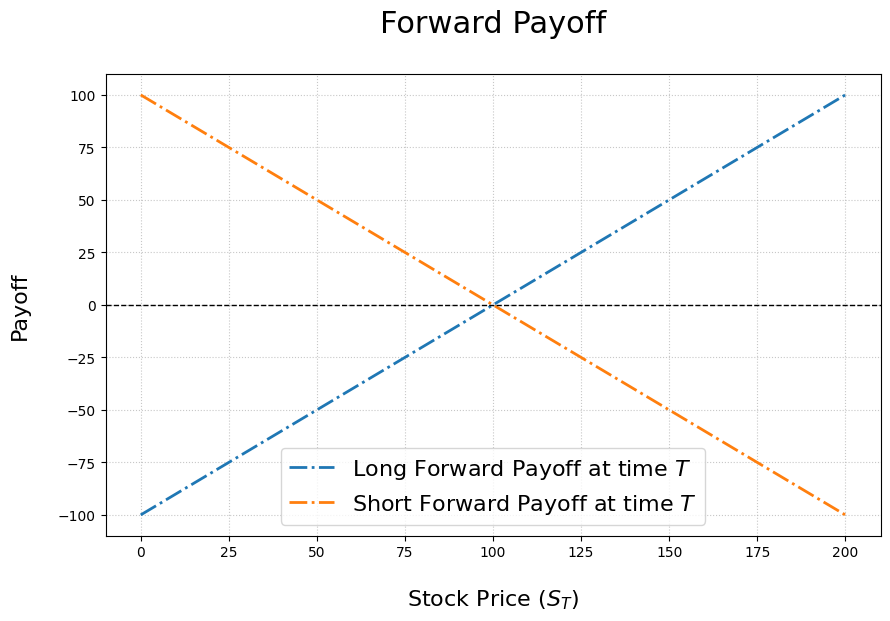

In [18]:
extended_layout = {
    'title': 'Forward Payoff',
    'x_label': 'Stock Price ($S_{T}$)',
    'y_label': 'Payoff',
    'figsize': (10, 6),          
    'grid': True,               
    'linewidth': 2,             
    'linestyle': '-.',            
    'title_fontsize': 22
}

my_plotter(
    x_stock_price, 
    [y_forward_payoff, y_forward_payoff__short], 
    layout=extended_layout, 
    names=['Long Forward Payoff at time $T$', 'Short Forward Payoff at time $T$'])

### Task b

In [22]:
import numpy as np
from scipy.stats import norm
from typing import Union, List
import matplotlib.pyplot as plt

def black_scholes_eur_call_with_greeks(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> dict:
    """
    Black-Scholes pricer of European call option on non-dividend-paying stock
    Returns a dictionary containing the option price and the Greeks.

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    """
    assert sigma > 0
    assert T > 0
    
    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    
    d2_vec = d1_vec - sigma * T**0.5
    
    N_d1_vec = norm.cdf(d1_vec)
    
    N_d2_vec = norm.cdf(d2_vec)
    
    n_d1_vec = norm.pdf(d1_vec)

    price = N_d1_vec * S0 - K * np.exp(-r * T) * N_d2_vec

    delta = N_d1_vec
    vega = S0 * n_d1_vec * np.sqrt(T)
    theta = -S0 * n_d1_vec * sigma / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * N_d2_vec
    rho = K * T * np.exp(-r * T) * N_d2_vec
    gamma = n_d1_vec / (S0 * sigma * np.sqrt(T))

    return {
        "price": price,
        "delta": delta,
        "vega": vega,
        "theta": theta,
        "rho": rho,
        "gamma": gamma
    }

### Task c


In [23]:
import numpy as np
from scipy.stats import norm
from typing import Union, List

def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> np.ndarray:
    """
    Black-Scholes pricer of European put option on non-dividend-paying stock

    param r: risk-free interest rate (which is constant)
    param T: time to maturity (in years)
    param S0: initial spot price of the underlying stock
    param sigma: volatility of the underlying stock
    param K: strike price (or prices)
    """
    assert sigma > 0

    K = np.array([K]) if isinstance(K, float) else np.array(K)

    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5

    N_minus_d1_vec = norm.cdf(-d1_vec)
    N_minus_d2_vec = norm.cdf(-d2_vec)

    return K * np.exp(-r * T) * N_minus_d2_vec - S0 * N_minus_d1_vec

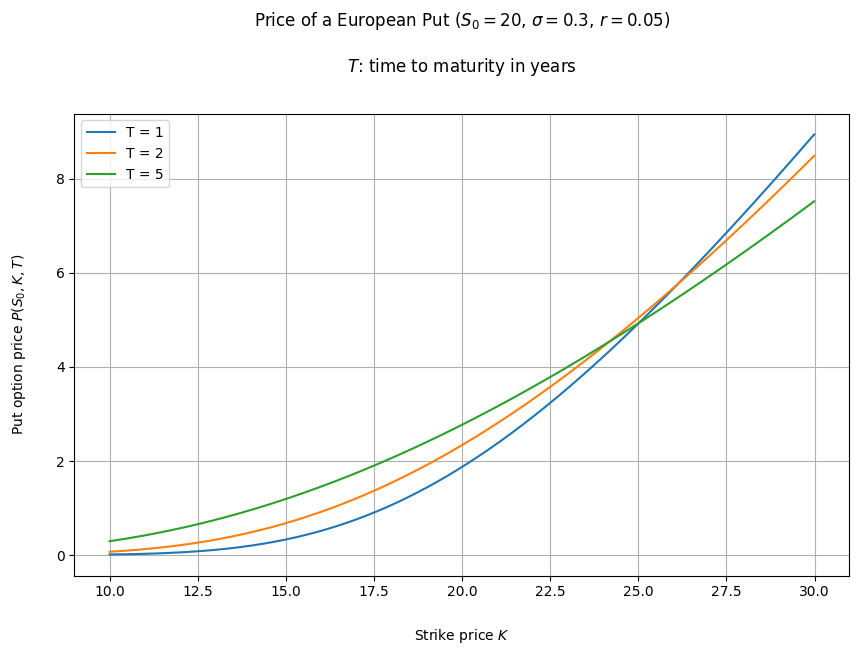

In [25]:
    K_vec = np.arange(10, 30, 0.01)
    T_vec = [1.0, 2.0, 5.0]

    prices_to_plot = []
    for _T in T_vec:
        prices_to_plot.append(black_scholes_eur_put(r=0.05, T=_T, S0=20.0, sigma=0.3, K=K_vec))

    plt.figure(figsize=(10, 6))

    for prices, T in zip(prices_to_plot, T_vec):
        plt.plot(K_vec, prices, label=f"T = {int(T)}")

    plt.title(
        'Price of a European Put ($S_0 = 20$, $\\sigma = 0.3$, $r = 0.05$)\n\n'
        '$T$: time to maturity in years'
    )

    plt.xlabel('Strike price $K$')
    plt.ylabel('Put option price $P(S_0,K,T)$')

    plt.legend()
    plt.grid(True)
    plt.show()

### Task d

In [41]:
import numpy as np
from scipy.stats import norm
from typing import Union, List

def black_scholes_eur_call(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> np.ndarray:
    assert sigma > 0
    K = np.array([K]) if isinstance(K, float) else np.array(K)
    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5
    return norm.cdf(d1_vec) * S0 - K * np.exp(-r*T) * norm.cdf(d2_vec)

def black_scholes_eur_put(r: float, T: float, S0: float, sigma: float, K: Union[float, List[float], np.ndarray]) -> np.ndarray:
    assert sigma > 0
    K = np.array([K]) if isinstance(K, float) else np.array(K)
    d1_vec = ( np.log( S0 / K ) + ( r + 0.5 * sigma**2 ) * T ) / ( sigma * T**0.5 )
    d2_vec = d1_vec - sigma * T**0.5
    return K * np.exp(-r * T) * norm.cdf(-d2_vec) - S0 * norm.cdf(-d1_vec)


def check_put_call_parity():
    S0 = 100.0
    r = 0.05
    sigma = 0.2
    T = 1.0

    K_vec = np.arange(80, 101, 10) 

    call_prices = black_scholes_eur_call(r, T, S0, sigma, K_vec)
    put_prices = black_scholes_eur_put(r, T, S0, sigma, K_vec)

    LHS = call_prices - put_prices
    RHS = S0 - K_vec * np.exp(-r * T)


    print(f"{'Strike (K)':>10} | {'C - P (LHS)':>15} | {'S0 - K*e^(-rT) (RHS)':>20} | {'Equal?':>10}")
   

    for i in range(len(K_vec)):
        k = K_vec[i]
        lhs_val = LHS[i]
        rhs_val = RHS[i]
        is_equal = np.isclose(lhs_val, rhs_val)
        
        print(f"{k:10.2f} | {lhs_val:15.6f} | {rhs_val:20.6f} | {str(is_equal):>10}")


In [42]:
check_put_call_parity()

Strike (K) |     C - P (LHS) | S0 - K*e^(-rT) (RHS) |     Equal?
     80.00 |       23.901646 |            23.901646 |       True
     90.00 |       14.389352 |            14.389352 |       True
    100.00 |        4.877058 |             4.877058 |       True
